**Principie Cyubahiro**
---
**BSE - African Leadership University**

**Machine Learning Techniques 1**

**Summative Project**

**Introduction**
---
The likes of high-resource languages like English and French are abundantly available, and the most NLP systems have been built on the top of that. Unlike those, African languages like Kinyarwanda on the otherhand has less available data, few pretrained models , and limited tooling. This project aims to work on such a gap.

The task is news classification for Kinyarwanda: given a news article written in Kinyarwanda, predict which of 14 categories it belongs to (politics, sport, economy, health, entertainment, history, technology, tourism, culture, fashion, religion, environment, education, relationship). It is a multi-class classification problem.

The data comes from KINNEWS, released by Niyongabo et al. (2020) through a public GitHub repository (https://github.com/Andrews2017/KINNEWS-and-KIRNEWS-Corpus). It consists of 21,268 news articles collected from 15 websites and 5 newspapers in Rwanda. The authors shipped a raw version with full metadata and a cleaned version with text already preprocessed. I use the raw version so I can own every preprocessing step by myself.

There are possible practical uses of this system to be built. For example; Rwandan news sites like igihe.com organise content under category sections, and today each article is tagged by hand before publishing. A classifier that reads an article and returns a predicted category automates that step.

The notebook follows this flow: setup and data loading, exploratory analysis, preprocessing, train/validation/test split, two classical baselines (TF-IDF with Logistic Regression and Linear SVM), four deep sequential models (BiGRU and 1D CNN with three different word embeddings), evaluation using accuracy and macro precision, recall, F1-score, error analysis on the best model, and export of that best model for a Streamlit web app.

## 1. Setup

Import the relevant libraries, and install one that does not come with google colab. Mount the google drive to access the dataset, set the paths to be used throughout the notebook and also setting seed for similar output reproducebility.

In [1]:
!pip install -q gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.8 MB/s eta 0:00:00


In [2]:
import os
import re
import json
import pickle
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, GRU, Conv1D,
    GlobalMaxPooling1D, Dense, Dropout, SpatialDropout1D,
)

import gensim
from gensim.models import Word2Vec

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print('TensorFlow', tf.__version__)
print('Gensim', gensim.__version__)
print('GPU available:', len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow 2.21.0
Gensim 4.4.0
GPU available: True


### 1.1 Mount google drive


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.2 Paths setup

In [4]:
BASE = '/content/drive/MyDrive/KINNEWS'
RAW_DIR = f'{BASE}/raw'
EMB_DIR = f'{BASE}/embeddings'
STOPWORDS_PATH = f'{BASE}/stopwords.txt'
CLASSES_PATH = f'{BASE}/classes.txt'
OUT_DIR = f'{BASE}/outputs'
ART_DIR = f'{OUT_DIR}/artifacts'
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
Path(ART_DIR).mkdir(parents=True, exist_ok=True)

CONFIG = {
    'MAX_VOCAB': 80000,
    'MAX_LEN': 650,
    'BATCH': 64,
    'EPOCHS': 20,
    'PATIENCE': 4,
    'MIN_TOKEN_LEN': 2,
}
print('Paths OK. Outputs ->', OUT_DIR)

Paths OK. Outputs -> /content/drive/MyDrive/KINNEWS/outputs


## 2. Load the dataset

I only take daatset from raw/ folder, the ```train.csv``` and ```test/csv```. The raw version has six columns (`label, kin_label, en_label, url, title, content`). I keep `label`, `title`, `content` since that is what the task needs. Class indices run from 1 to 14 in the CSV, so I store an `index -> name` dictionary now and reuse it for every plot and table.

In [ ]:
df_train = pd.read_csv(f'{RAW_DIR}/train.csv')
df_test = pd.read_csv(f'{RAW_DIR}/test.csv')

In [ ]:
df_train.head(5)

,label,kin_label,en_label,url,title,content
0,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Yihakanye uwo yabyaye animisha na nyina ibyo y...,Icyatumye amwihakana ngo ni uko yanze kujya a...
1,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Barasaba ko ba kavukire boroherezwa ntibakomez...,Iyi nama yateraniye mu cyumba cy’inama cya Bo...
2,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Abantu 9 bashakishwa cyane na ICTR na USA bash...,Leta zunze Ubumwe z’Amerika kandi zanijeje uz...
3,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Yihakanye uwo yabyaye animisha na nyina ibyo y...,Icyatumye amwihakana ngo ni uko yanze kujya a...
4,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Barasaba ko ba kavukire boroherezwa ntibakomez...,Iyi nama yateraniye mu cyumba cy’inama cya Bo...


In [ ]:
df_test.head(5)

,label,kin_label,en_label,url,title,content
0,6,amateka,history,http://muhabura.rw/amakuru/amateka/article/ama...,Gatsibo : Tariki 11 Mata 1994 ni itariki itazi...,Gatete Jean Baptiste wari Burugumesitiri wa K...
1,6,amateka,history,http://muhabura.rw/amakuru/amateka/article/ku-...,"Ku wa 10 Mata 1994 : Abatutsi bagera ku 10,000...",Kwibuka ku nshuro ya 26 Jenoside yakorewe Ab...
2,6,amateka,history,http://muhabura.rw/amakuru/amateka/article/kwi...,#KWIBUKA 26 : Tariki 9 Mata 1994 Abasirikare...,"Uyu munsi ni tariki 9 Mata 2020 , hashize imy..."
3,5,imyidagaduro,entertainment,http://muhabura.rw/amakuru/imyidagaduro/articl...,Burundi:Umufasha wa Perezida Nkurunziza yakoze...,"Denise Nkurunziza, umufasha wa Perezida Peter..."
4,5,imyidagaduro,entertainment,http://muhabura.rw/amakuru/imyidagaduro/articl...,Burundi:Umunyamakuru Landry Promoter ukunze gu...,Mu minsi ishize ku mbuga nkoranyambaga hazeng...


### Checking the missing values

In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17014 entries, 0 to 17013
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   label      17014 non-null  int64 
 1   kin_label  17014 non-null  object
 2   en_label   17014 non-null  object
 3   url        17014 non-null  object
 4   title      17014 non-null  object
 5   content    17014 non-null  object
dtypes: int64(1), object(5)
memory usage: 797.7+ KB


In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4254 entries, 0 to 4253
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   label      4254 non-null   int64 
 1   kin_label  4254 non-null   object
 2   en_label   4254 non-null   object
 3   url        4254 non-null   object
 4   title      4254 non-null   object
 5   content    4249 non-null   object
dtypes: int64(1), object(5)
memory usage: 199.5+ KB


In [ ]:
df_filtered = df_test[df_test['content'].isna()] # Check what exactly is missing
df_filtered

,label,kin_label,en_label,url,title,content
4227,11,iyobokamana,religion,http://www.igihe.com/twinigure/caricature/arti...,"Ilayidi, umunsi w’amafunguro kuri bamwe!",NaN
4228,9,umuco,culture,http://www.igihe.com/twinigure/caricature/arti...,Gukoresha nabi Ikinyarwanda bikomeje gufata in...,NaN
4231,9,umuco,culture,http://www.igihe.com/twinigure/caricature/arti...,Uko Abanyarwanda bakwiriye kwizihiza Umuganura,NaN
4236,7,ikoranabuhanga,technology,http://www.igihe.com/twinigure/caricature/arti...,Internet ya 4G imaze kwigarurira imitima ya be...,NaN
4253,11,iyobokamana,religion,http://www.igihe.com/twinigure/caricature/arti...,Abayoboke ba Kiliziya Gatolika bari kugabanyuk...,NaN


### Recap so far

Since the test dataset has some missing values in content column, and that is the most useful for thie problem, it is reasonable to drop those rows and remain with the ones with full required information.

In [ ]:
df_test = df_test.dropna() # Drop the rows with missing content columns values
df_test.info() # New test dataframe will be a total of 6 rows and 4249

<class 'pandas.core.frame.DataFrame'>
Index: 4249 entries, 0 to 4252
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   label      4249 non-null   int64 
 1   kin_label  4249 non-null   object
 2   en_label   4249 non-null   object
 3   url        4249 non-null   object
 4   title      4249 non-null   object
 5   content    4249 non-null   object
dtypes: int64(1), object(5)
memory usage: 232.4+ KB


### Final datasets look

In [ ]:
with open(CLASSES_PATH, 'r', encoding='utf-8') as f:
    CLASS_NAMES = [line.strip() for line in f if line.strip()]
LABEL_MAP = {i + 1: name for i, name in enumerate(CLASS_NAMES)}

print('Train rows:', len(df_train))
print('Test rows:', len(df_test))
print('Columns:', list(df_train.columns))
print('Classes:', CLASS_NAMES)

Train rows: 17014
Test rows: 4249
Columns: ['label', 'kin_label', 'en_label', 'url', 'title', 'content']
Classes: ['politics', 'sport', 'economy', 'health', 'entertainment', 'history', 'technology', 'tourism', 'culture', 'fashion', 'religion', 'environment', 'education', 'relationship']


## 3. Exploratory analysis

Before building models, I want to understand the data: how balanced the classes are, how long the articles tend to be, and what the vocabulary looks like. These numbers help me make decisions such as; the padding length, the vocab cap, and whether class imbalance needs to be addressed with weighting or metric choice.

### 3.1 Class distribution

Count how many articles fall into each class, in both train and test. That will help me in deciding on what evaluation metrics are better. For example; if one or two classes dominate, I will report macro-averaged F1 as the primary metric so small classes are not drowned out.

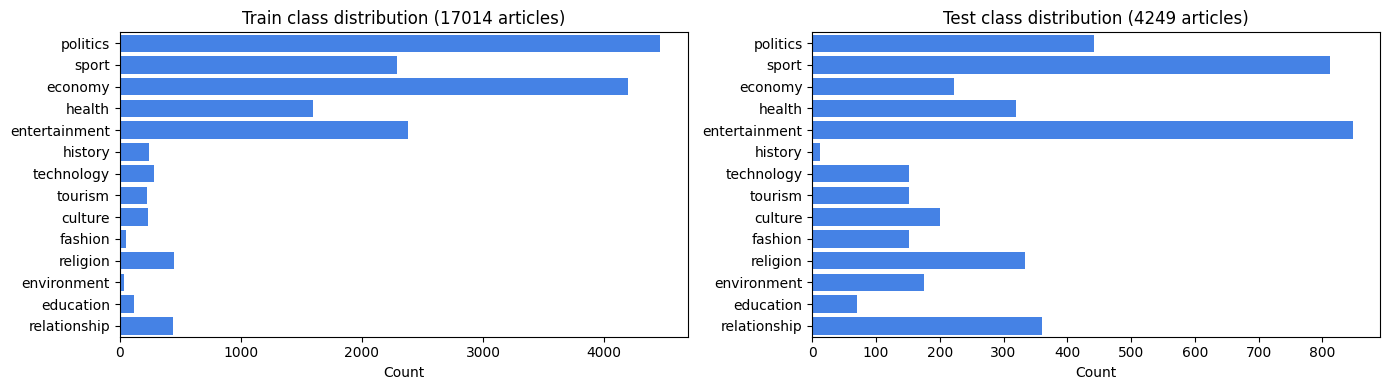


Train class counts:
               count       %
label                       
politics        4466  26.25%
sport           2292  13.47%
economy         4196  24.66%
health          1594   9.37%
entertainment   2381  13.99%
history          244   1.43%
technology       287   1.69%
tourism          226   1.33%
culture          233   1.37%
fashion           54   0.32%
religion         447   2.63%
environment       38   0.22%
education        116   0.68%
relationship     440   2.59%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, df, name in zip(axes, [df_train, df_test], ['Train', 'Test']):
    counts = df['label'].map(LABEL_MAP).value_counts().reindex(CLASS_NAMES).fillna(0)
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color='#2b7cff')
    ax.set_title(f'{name} class distribution ({len(df)} articles)')
    ax.set_xlabel('Count')
    ax.set_ylabel('')
plt.tight_layout(); plt.show()

print('\nTrain class counts:')
counts = df_train['label'].map(LABEL_MAP).value_counts().reindex(CLASS_NAMES)
print(pd.concat([counts.rename('count'), (counts / counts.sum() * 100).map('{:.2f}%'.format).rename('%')], axis=1))

### 3.2 Article length

I check the number of words in the raw concatenation of title and content for every article. The 95th percentile tells me how long to pad sequences without truncating too much.

Length stats (words):
count    17014.0
mean       287.1
std        248.0
min         19.0
50%        237.0
75%        331.0
90%        469.0
95%        586.0
99%       1053.0
max      11583.0
Name: raw_text, dtype: float64


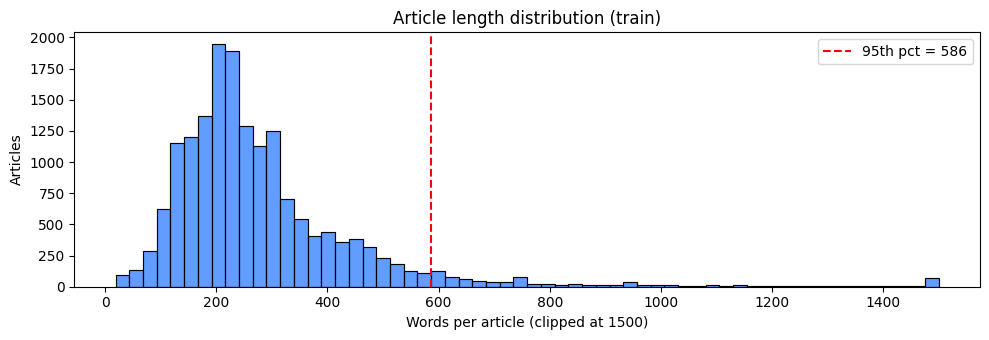

In [ ]:
df_train['raw_text'] = (df_train['title'] + ' ' + df_train['content']).astype(str)
df_test['raw_text']  = (df_test['title'] + ' ' + df_test['content']).astype(str)

lengths = df_train['raw_text'].str.split().apply(len)
print('Length stats (words):')
print(lengths.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(1))

plt.figure(figsize=(10, 3.5))
sns.histplot(lengths.clip(upper=1500), bins=60, color='#2b7cff')
plt.axvline(lengths.quantile(0.95), color='red', linestyle='--',
            label=f'95th pct = {int(lengths.quantile(0.95))}')
plt.xlabel('Words per article (clipped at 1500)'); plt.ylabel('Articles'); plt.legend()
plt.title('Article length distribution (train)'); plt.tight_layout(); plt.show()

### Recap so far

95% of the articles have less than 586 words

### 3.3 Vocabulary size and sample articles

A rough look at how many unique tokens are in the training set, and one sample article per class so I can sanity-check the labels.

In [ ]:
vocab = Counter()
for txt in df_train['raw_text']:
    vocab.update(txt.lower().split())
print('Unique tokens (train):', len(vocab))
print('Top 20 tokens:', vocab.most_common(20))

Unique tokens (train): 247977
Top 20 tokens: [('mu', 178151), ('ko', 90470), ('ku', 74012), ('muri', 59951), ('na', 48174), ('wa', 45197), ('ya', 36729), ('rwanda', 28238), ('ari', 27890), ('ngo', 27795), ('kuri', 26537), ('ni', 25873), ('no', 22774), ('kandi', 21800), ('yo', 21299), ('kuko', 20383), ('ndetse', 19360), ('uyu', 18108), ('ariko', 17344), ('avuga', 16029)]


In [ ]:
for label, name in LABEL_MAP.items():
    row = df_train[df_train['label'] == label].head(1)
    if len(row):
        text = row['raw_text'].values[0][:220].replace('\n', ' ')
        print(f'[{label}] {name}: {text}...')

[1] politics: John Arrow Bockarie yishimiye uko Abanyasiyeraleone bafungiye i Mpanga babayeho  John Arrow Bockarie yasuye izi mfungwa mu rwego kwirebera iko zibayeho nyuma y’uko bimwe mubitangazamakuru bitangaje amakuru avuga ko zifas...
[2] sport: Abanyarwanda batuye muri Canada bibutse abazize Jenoside yakorewe Abatutsi  Igikorwa cyo kwibuka kitabiriwe kandi n’abahagarariye ibihugu byabo muri Canada n’izindi nshuti. Uyu muhango watangijwe n’urugendo (walk to reme...
[3] economy: Hadutse indwara y’imyumbati ishobora kuba icyorezo – FAO  Ishami y’umuryango w’abibumbye ryita ku biribwa ndetse n’ubuhinzi(FAO) rivuga ko indwara yitwa Cassava Brown Streak Disease (CBSD) ishobora kuba icyorezo. Ibyo ba...
[4] health: Harateganywa ubushakashatsi ku dukingirizo tuberanye n’ingimbi  Ibi ni bimwe mu byavugiwe mu kiganiro n’abanyamakuru kuri uyu wa kane tariki ya 03/11/2011 akaba ari ikiganiro cyateguwe n’ikigo cy’igihugu gishinzwe ubuzim...
[5] entertainment: Rafiki avuga ko muri PGGSS season 2

### 3.4 Most distinctive words per class

Which words carry the strongest signal for each category? I treat every article in a class as part of one big "class document", then fit a TF-IDF vectoriser across the 14 class documents. A word scores high for a class when it appears often in that class and rarely in the others.

This gives a concrete feel for what the model should be learning. It also lets me spot shortcuts the model might take: if one keyword appears in nearly every article of a class, a model can memorise that single token and still score well on the class without learning anything general.

In [ ]:
with open(STOPWORDS_PATH, 'r', encoding='utf-8') as f:
    _sw = [w.strip().lower() for w in f if w.strip()]

class_docs = (
    df_train.groupby('label')['raw_text']
    .apply(lambda s: ' '.join(s.astype(str)))
    .reindex(range(1, len(CLASS_NAMES) + 1))
    .fillna('')
    .values
)

class_vec = TfidfVectorizer(
    lowercase=True,
    stop_words=_sw,
    min_df=5,
    max_df=0.9,
    token_pattern=r'[a-z]{2,}',
)
class_tfidf = class_vec.fit_transform(class_docs)
vocab_arr = np.array(class_vec.get_feature_names_out())

TOP_K = 10
print(f'Top {TOP_K} most distinctive words per class (class-level TF-IDF).')
print('A word ranks high when it appears often in this class and rarely in the others.\n')
for i, cls_name in enumerate(CLASS_NAMES):
    row = class_tfidf[i].toarray().ravel()
    top_idx = row.argsort()[::-1][:TOP_K]
    print(f'{cls_name:14s}: {", ".join(vocab_arr[top_idx])}')

Top 10 most distinctive words per class (class-level TF-IDF).
A word ranks high when it appears often in this class and rarely in the others.

politics      : jenoside, abatutsi, icumu, ingabo, kwibuka, yakorewe, abacitse, urukiko, fdlr, icyunamo
sport         : ikipe, rayon, fc, abakinnyi, apr, sports, umukino, amakipe, imikino, shampiyona
economy       : ibiciro, banki, sacco, ubuhinzi, bihingwa, toni, ingendo, miliyari, inguzanyo, koperative
health        : ndwara, sida, muhabura, uburaya, coronavirus, mpuzabitsina, umugore, ebola, uburwayi, imiti
entertainment : indirimbo, ndirimbo, abahanzi, miss, umuhanzi, boys, album, dream, gitaramo, muzika
history       : abatutsi, jenoside, komini, interahamwe, ingabo, umwami, mata, ingoma, ubwicanyi, bahungiye
technology    : mudasobwa, apple, steve, telefoni, serivisi, telefone, indege, uruganda, zisanzwe, caf
tourism       : pariki, parike, ingagi, rdb, nyungwe, amahoteli, rwigamba, ubukerarugendo, ibirunga, gusura
culture       : jenoside

## 4. Preprocessing

Steps applied to every article, in order:

1. Combine title and content into one string (title often carries the strongest category signal).
2. Lowercase.
3. Replace URLs with a space, then replace anything that is not a lowercase letter or whitespace with a space (this removes digits, punctuation and Latin uppercase that leaked in).
4. Collapse multiple spaces.
5. Tokenise on whitespace.
6. Drop tokens listed in the KINNEWS stopword set.
7. Drop tokens shorter than `MIN_TOKEN_LEN` characters.
8. Rejoin into a cleaned string.

The function is pure and deterministic. I will reuse the exact same function in the Streamlit app so training and inference preprocess the same way.

In [ ]:
with open(STOPWORDS_PATH, 'r', encoding='utf-8') as f:
    STOPWORDS = {w.strip().lower() for w in f if w.strip()}
print('Stopwords loaded:', len(STOPWORDS))

URL_RE = re.compile(r'https?://\S+|www\.\S+')
NON_ALPHA_RE = re.compile(r'[^a-z\s]')
MULTISPACE_RE = re.compile(r'\s+')

def preprocess(text, stopwords=STOPWORDS, min_len=CONFIG['MIN_TOKEN_LEN']):
    if not isinstance(text, str):
        return ''
    t = text.lower()
    t = URL_RE.sub(' ', t)
    t = NON_ALPHA_RE.sub(' ', t)
    t = MULTISPACE_RE.sub(' ', t).strip()
    toks = [w for w in t.split() if w not in stopwords and len(w) >= min_len]
    return ' '.join(toks)

sample = df_train['raw_text'].iloc[0]
print('BEFORE:', sample[:200], '...')
print('AFTER :', preprocess(sample)[:200], '...')

Stopwords loaded: 80
BEFORE: Yihakanye uwo yabyaye animisha na nyina ibyo yagombaga guhabwa nk’abandi batishoboye  Icyatumye amwihakana ngo ni uko yanze kujya akomeza kuryamana nawe, nk’uko nyirubwite abivuga. Ati: ”Umugabo wanjy ...
AFTER : yihakanye yabyaye animisha nyina yagombaga guhabwa abandi batishoboye icyatumye amwihakana yanze kujya akomeza kuryamana nyirubwite abivuga umugabo wanjye iserazerano uganda nkaba narabyaranye twabyar ...


In [ ]:
df_train['text'] = df_train['raw_text'].apply(preprocess)
df_test['text']  = df_test['raw_text'].apply(preprocess)

# drop rows that became empty after cleaning
df_train = df_train[df_train['text'].str.len() > 0].reset_index(drop=True)
df_test  = df_test[df_test['text'].str.len() > 0].reset_index(drop=True)
print('After cleaning:', len(df_train), 'train rows,', len(df_test), 'test rows')

df_train[['label', 'text']].to_parquet(f'{ART_DIR}/train_clean.parquet', index=False)
df_test[['label', 'text']].to_parquet(f'{ART_DIR}/test_clean.parquet', index=False)
print('Saved cleaned splits to', ART_DIR)

After cleaning: 17014 train rows, 4249 test rows
Saved cleaned splits to /content/drive/MyDrive/KINNEWS/outputs/artifacts


In [ ]:
new_df_train = pd.read_parquet("/content/drive/MyDrive/KINNEWS/outputs/artifacts/train_clean.parquet")
print(new_df_train.to_numpy()[3])

[6
 'yihakanye yabyaye animisha nyina yagombaga guhabwa abandi batishoboye icyatumye amwihakana yanze kujya akomeza kuryamana nyirubwite abivuga umugabo wanjye iserazerano uganda nkaba narabyaranye twabyaranye umuyobozi umudugudu kabuye nyuma tubyaraniye yashatse gukomeza kunsambanya angire akarima ke ndanga mubyeyi avuga yarabyaranye yunvaga atakomeza gukora amakosa guca umugabo inyuma adahari akomeza avuga mugabo yakomeje kumubangamira buyobozi bazaga kubarurra abatishoboye bagombaga gufashwa vup bantu bagombaga guhabwa ibibanza amabati kugira babone kuba kuko ntaho bafite ho kuba urutonde abazahabwa bikoresho rurangiye njye nasanze ntaruriho kandi warukoraga abaturanyi banjye bemezaga nanjye ngomba gufashwa ikimbabaza andenganya kandi wakagombye kundenganura mubyeyi yivugira mwana basa cyane ndetse abana mugabo basa avuga yagerageje kugeza kibazo nzego zitandukanye ariko ntibamufashe nyuma akaza kukigeza murenge kigomba gukirkiranwa umuyobozi wawo maniraguha avuga kubera ibyamubayeh

### Article length after preprocessing

In [ ]:
pre_lengths = df_train['text'].str.split().apply(len)
print('Preprocessed length stats:')
print(pre_lengths.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(1))

pre_vocab = Counter()
for txt in df_train['text']:
    pre_vocab.update(txt.split())
sorted_counts = sorted(pre_vocab.values(), reverse=True)
cumulative = np.cumsum(sorted_counts) / sum(sorted_counts)
print(f'\nUnique preprocessed tokens: {len(pre_vocab):,}')
for pct in [0.90, 0.95, 0.98, 0.99]:
    k = int(np.searchsorted(cumulative, pct)) + 1
    print(f'  top {k:>7,d} words cover {int(pct*100)}% of all token occurrences')

Preprocessed length stats:
count    17014.0
mean       213.3
std        183.5
min         13.0
50%        178.0
75%        243.0
90%        352.0
95%        436.0
99%        770.0
max       8494.0
Name: text, dtype: float64

Unique preprocessed tokens: 150,348
  top  17,012 words cover 90% of all token occurrences
  top  35,440 words cover 95% of all token occurrences
  top  77,759 words cover 98% of all token occurrences
  top 114,054 words cover 99% of all token occurrences


## 5. Train/validation/test split

The authors already fixed the test split (4,254 articles which I dropped NaN values to end up with 4249 articles). I keep that test set untouched and use it only for the final evaluation of every experiment. From the 17,014 train articles I carve a stratified 10 percent validation set, which keeps the class ratios in train and val similar.

In [ ]:
y_full = df_train['label'].values
X_full = df_train['text'].values

X_tr_txt, X_val_txt, y_tr, y_val = train_test_split(
    X_full, y_full, test_size=0.10, stratify=y_full, random_state=SEED,
)
X_te_txt = df_test['text'].values
y_te = df_test['label'].values

# labels in Keras need to start at 0
y_tr_idx  = y_tr  - 1
y_val_idx = y_val - 1
y_te_idx  = y_te  - 1

print('train:', len(X_tr_txt), '| val:', len(X_val_txt), '| test:', len(X_te_txt))
print('train label counts (stratified):')
print(pd.Series(y_tr).map(LABEL_MAP).value_counts().reindex(CLASS_NAMES))

np.save(f'{ART_DIR}/y_tr.npy', y_tr_idx)
np.save(f'{ART_DIR}/y_val.npy', y_val_idx)
np.save(f'{ART_DIR}/y_te.npy', y_te_idx)
pd.DataFrame({'text': X_tr_txt}).to_parquet(f'{ART_DIR}/X_tr_txt.parquet')
pd.DataFrame({'text': X_val_txt}).to_parquet(f'{ART_DIR}/X_val_txt.parquet')
pd.DataFrame({'text': X_te_txt}).to_parquet(f'{ART_DIR}/X_te_txt.parquet')

train: 15312 | val: 1702 | test: 4249
train label counts (stratified):
politics         4019
sport            2063
economy          3776
health           1435
entertainment    2143
history           220
technology        258
tourism           203
culture           210
fashion            49
religion          402
environment        34
education         104
relationship      396
Name: count, dtype: int64


## 6. Tokenizer and padded sequences

A Keras `Tokenizer` fit on the training set only (never on validation or test, which would leak information if done). I cap the vocabulary at `CONFIG['MAX_VOCAB']` tokens and pad each sequence to `CONFIG['MAX_LEN']` so every input has the same shape. The tokenizer is pickled for the Streamlit app.

In [ ]:
tokenizer = Tokenizer(num_words=CONFIG['MAX_VOCAB'], oov_token='<OOV>')
tokenizer.fit_on_texts(X_tr_txt)

X_tr_seq  = pad_sequences(tokenizer.texts_to_sequences(X_tr_txt),  maxlen=CONFIG['MAX_LEN'], padding='post', truncating='post')
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(X_val_txt), maxlen=CONFIG['MAX_LEN'], padding='post', truncating='post')
X_te_seq  = pad_sequences(tokenizer.texts_to_sequences(X_te_txt),  maxlen=CONFIG['MAX_LEN'], padding='post', truncating='post')

print('Tokenizer vocab (effective):', min(len(tokenizer.word_index) + 1, CONFIG['MAX_VOCAB']))
print('Sequence shapes:', X_tr_seq.shape, X_val_seq.shape, X_te_seq.shape)

np.save(f'{ART_DIR}/X_tr_seq.npy',  X_tr_seq)
np.save(f'{ART_DIR}/X_val_seq.npy', X_val_seq)
np.save(f'{ART_DIR}/X_te_seq.npy',  X_te_seq)
with open(f'{ART_DIR}/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

Tokenizer vocab (effective): 80000
Sequence shapes: (15312, 650) (1702, 650) (4249, 650)


## 7. Pretrained Word2Vec (provided)

The KINNEWS authors released two pretrained Word2Vec models for Kinyarwanda, one 50-dimensional and one 100-dimensional. The files are plain text, one word per line followed by its vector components separated by spaces, and no header. I load each one into a dict and build a Keras embedding matrix of shape `(vocab_size, dim)` by looking up every token in my tokenizer vocab.

In [ ]:
def load_w2v_text(path):
    emb = {}
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip().split(' ')
            if len(parts) < 10:  # skip empty or malformed lines
                continue
            emb[parts[0]] = np.asarray(parts[1:], dtype='float32')
    return emb

def build_embedding_matrix(emb, word_index, dim, max_vocab):
    size = min(len(word_index) + 1, max_vocab)
    matrix = np.zeros((size, dim), dtype='float32')
    found = 0
    for word, i in word_index.items():
        if i >= max_vocab:
            continue
        v = emb.get(word)
        if v is not None and v.shape[0] == dim:
            matrix[i] = v
            found += 1
    return matrix, found, size

In [ ]:
emb_pre_50 = load_w2v_text(f'{EMB_DIR}/W2V-Kin-50.txt')
emb_pre_100 = load_w2v_text(f'{EMB_DIR}/W2V-Kin-100.txt')
print('Pretrained 50d vocab :', len(emb_pre_50))
print('Pretrained 100d vocab:', len(emb_pre_100))

M_pre50, hit50, vsize = build_embedding_matrix(emb_pre_50,  tokenizer.word_index, 50,  CONFIG['MAX_VOCAB'])
M_pre100, hit100, _   = build_embedding_matrix(emb_pre_100, tokenizer.word_index, 100, CONFIG['MAX_VOCAB'])
print(f'Matrix shapes: 50d={M_pre50.shape}  100d={M_pre100.shape}  (vocab size {vsize})')
print(f'Coverage: 50d {hit50}/{vsize} = {hit50/vsize:.1%} | 100d {hit100}/{vsize} = {hit100/vsize:.1%}')

np.save(f'{ART_DIR}/emb_pre_50.npy', M_pre50)
np.save(f'{ART_DIR}/emb_pre_100.npy', M_pre100)

Pretrained 50d vocab : 54455
Pretrained 100d vocab: 54455
Matrix shapes: 50d=(80000, 50)  100d=(80000, 100)  (vocab size 80000)
Coverage: 50d 42969/80000 = 53.7% | 100d 42969/80000 = 53.7%


## 8. Own-trained Word2Vec

To compare the authors' pretrained embeddings against embeddings learned only from the KINNEWS training corpus, I train a 50d Word2Vec with gensim on the cleaned training texts. Same dimension as the authors' 50d so the comparison is fair.

In [ ]:
sents = [t.split() for t in X_tr_txt]
w2v_own = Word2Vec(
    sentences=sents, vector_size=50, window=5, min_count=2,
    workers=4, sg=1, epochs=10, seed=SEED,
)
print('Own W2V vocab:', len(w2v_own.wv))

own_dict = {w: w2v_own.wv[w] for w in w2v_own.wv.index_to_key}
M_own50, hit_own, _ = build_embedding_matrix(own_dict, tokenizer.word_index, 50, CONFIG['MAX_VOCAB'])
print(f'Own matrix shape: {M_own50.shape}  coverage {hit_own}/{vsize} = {hit_own/vsize:.1%}')
np.save(f'{ART_DIR}/emb_own_50.npy', M_own50)
w2v_own.save(f'{ART_DIR}/w2v_own.model')

Own W2V vocab: 70229
Own matrix shape: (80000, 50)  coverage 70229/80000 = 87.8%


## 9. Reload everything from disk

Everything above saves to Drive. The cell below reloads just the state needed to run or add experiments if needed more.

In [ ]:
tokenizer   = pickle.load(open(f'{ART_DIR}/tokenizer.pkl', 'rb'))
X_tr_seq    = np.load(f'{ART_DIR}/X_tr_seq.npy')
X_val_seq   = np.load(f'{ART_DIR}/X_val_seq.npy')
X_te_seq    = np.load(f'{ART_DIR}/X_te_seq.npy')
y_tr_idx    = np.load(f'{ART_DIR}/y_tr.npy')
y_val_idx   = np.load(f'{ART_DIR}/y_val.npy')
y_te_idx    = np.load(f'{ART_DIR}/y_te.npy')
X_tr_txt    = pd.read_parquet(f'{ART_DIR}/X_tr_txt.parquet').iloc[:, 0].values
X_val_txt   = pd.read_parquet(f'{ART_DIR}/X_val_txt.parquet').iloc[:, 0].values
X_te_txt    = pd.read_parquet(f'{ART_DIR}/X_te_txt.parquet').iloc[:, 0].values
M_pre50     = np.load(f'{ART_DIR}/emb_pre_50.npy')
M_pre100    = np.load(f'{ART_DIR}/emb_pre_100.npy')
M_own50     = np.load(f'{ART_DIR}/emb_own_50.npy')
NUM_CLASSES = len(CLASS_NAMES)
VOCAB_SIZE  = M_pre50.shape[0]
print('State reloaded. train seq:', X_tr_seq.shape, '| vocab size:', VOCAB_SIZE, '| classes:', NUM_CLASSES)

State reloaded. train seq: (15312, 650) | vocab size: 80000 | classes: 14


## 10. Shared helpers

One function to train a Keras model with early stopping, one function to compute the metrics I report everywhere, and one to save them. Keeping these in one place makes every experiment look the same, which is what makes the comparison fair.

In [ ]:
def train_keras(model, X_tr, y_tr, X_val, y_val, name,
                  epochs=CONFIG['EPOCHS'], batch=CONFIG['BATCH'],
                  patience=CONFIG['PATIENCE'], class_weight=None):
      es = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)
      hist = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                       epochs=epochs, batch_size=batch, callbacks=[es],
                       class_weight=class_weight, verbose=2)
      return hist

def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
    print(f'\n{name}')
    print(f'  accuracy        : {acc:.4f}')
    print(f'  macro precision : {p:.4f}')
    print(f'  macro recall    : {r:.4f}')
    print(f'  macro F1        : {f1:.4f}')
    return {'name': name, 'accuracy': acc, 'macro_precision': p, 'macro_recall': r, 'macro_f1': f1,
            'report': report, 'y_pred': y_pred.tolist()}

def save_metrics(m):
    tag = m['name'].lower().replace(' ', '_').replace('+', 'plus').replace('(', '').replace(')', '')
    with open(f'{OUT_DIR}/metrics_{tag}.json', 'w') as f:
        json.dump({k: v for k, v in m.items() if k != 'report'}, f, indent=2)
    with open(f'{OUT_DIR}/report_{tag}.txt', 'w') as f:
        f.write(m['report'])
    return tag

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
cw_arr = compute_class_weight('balanced',
                                classes=np.arange(NUM_CLASSES),
                                y=y_tr_idx)
CLASS_WEIGHT = dict(enumerate(cw_arr))
print('class weights:', {CLASS_NAMES[i]: round(w, 2) for i, w in CLASS_WEIGHT.items()})

class weights: {'politics': np.float64(0.27), 'sport': np.float64(0.53), 'economy': np.float64(0.29), 'health': np.float64(0.76), 'entertainment': np.float64(0.51), 'history': np.float64(4.97), 'technology': np.float64(4.24), 'tourism': np.float64(5.39), 'culture': np.float64(5.21), 'fashion': np.float64(22.32), 'religion': np.float64(2.72), 'environment': np.float64(32.17), 'education': np.float64(10.52), 'relationship': np.float64(2.76)}


## 11. Experiment 1: TF-IDF + Logistic Regression (baseline)

A standard classical baseline I chose for this text classification task. TF-IDF turns each document into a sparse weighted bag-of-words vector, logistic regression learns one linear boundary per class. Simple, fast, hard to beat on short news. (The main idea is to check if the task is keyword driven or maybe the sequence order would matter to classify the news)

In [ ]:
vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
X_tr_tfidf  = vectorizer.fit_transform(X_tr_txt)
X_val_tfidf = vectorizer.transform(X_val_txt)
X_te_tfidf  = vectorizer.transform(X_te_txt)
print('TF-IDF shape (train):', X_tr_tfidf.shape)

clf_lr = LogisticRegression(max_iter=1000, C=1.0, n_jobs=-1)
clf_lr.fit(X_tr_tfidf, y_tr_idx)
y_pred_lr = clf_lr.predict(X_te_tfidf)

m_e1 = evaluate(y_te_idx, y_pred_lr, 'E1 TF-IDF + LogReg')
save_metrics(m_e1)

with open(f'{ART_DIR}/vectorizer.pkl', 'wb') as f: pickle.dump(vectorizer, f)
with open(f'{ART_DIR}/clf_lr.pkl',    'wb') as f: pickle.dump(clf_lr, f)

TF-IDF shape (train): (15312, 50000)

E1 TF-IDF + LogReg
  accuracy        : 0.6540
  macro precision : 0.5424
  macro recall    : 0.4596
  macro F1        : 0.4151


###

In [ ]:
print("1. VAL vs TEST accuracy for the TF-IDF LogReg (same model, two splits)")
print("-" * 70)
y_pred_val_lr = clf_lr.predict(X_val_tfidf)
print(f"  val  accuracy: {accuracy_score(y_val_idx, y_pred_val_lr):.4f}")
print(f"  test accuracy: {accuracy_score(y_te_idx,  y_pred_lr):.4f}")

print("\n2. OOV rate on test (how many test tokens are unknown to the tokenizer)")
print("-" * 70)
word_index = tokenizer.word_index
in_full   = set(word_index.keys())
in_capped = {w for w, i in word_index.items() if i < CONFIG['MAX_VOCAB']}
test_tokens = [t for s in X_te_txt for t in s.split()]
total = len(test_tokens)
oov_full   = sum(1 for t in test_tokens if t not in in_full)
oov_capped = sum(1 for t in test_tokens if t not in in_capped)
print(f"  total test tokens              : {total:,}")
print(f"  not in training vocab at all   : {oov_full:,} ({oov_full/total:.1%})")
print(f"  not in top-{CONFIG['MAX_VOCAB']:,} training vocab : {oov_capped:,} ({oov_capped/total:.1%})")

print("\n3. Class distribution (train+val) vs test")
print("-" * 70)
train_dist = pd.Series(np.concatenate([y_tr_idx, y_val_idx])).value_counts(normalize=True).sort_index()
test_dist  = pd.Series(y_te_idx).value_counts(normalize=True).sort_index()
dist_df = pd.DataFrame({
    'class'    : CLASS_NAMES,
    'train_pct': (train_dist * 100).round(2).reindex(range(NUM_CLASSES)).fillna(0).values,
    'test_pct' : (test_dist  * 100).round(2).reindex(range(NUM_CLASSES)).fillna(0).values,
})
dist_df['diff'] = (dist_df['test_pct'] - dist_df['train_pct']).round(2)
print(dist_df.to_string(index=False))

print("\n4. Preprocessed length: train vs test")
print("-" * 70)
tr_len = pd.Series([len(t.split()) for t in np.concatenate([X_tr_txt, X_val_txt])])
te_len = pd.Series([len(t.split()) for t in X_te_txt])
print("  TRAIN:", tr_len.describe(percentiles=[0.5, 0.95]).round(1).to_dict())
print("  TEST :", te_len.describe(percentiles=[0.5, 0.95]).round(1).to_dict())

print("\n5. Five random test articles, sanity check the labels")
print("-" * 70)
for i in np.random.default_rng(SEED).choice(len(X_te_txt), 5, replace=False):
    print(f"\n  [true={CLASS_NAMES[y_te_idx[i]]}]  {X_te_txt[i][:220]}...")

1. VAL vs TEST accuracy for the TF-IDF LogReg (same model, two splits)
----------------------------------------------------------------------
  val  accuracy: 0.8778
  test accuracy: 0.6540

2. OOV rate on test (how many test tokens are unknown to the tokenizer)
----------------------------------------------------------------------
  total test tokens              : 1,159,295
  not in training vocab at all   : 79,250 (6.8%)
  not in top-80,000 training vocab : 102,902 (8.9%)

3. Class distribution (train+val) vs test
----------------------------------------------------------------------
        class  train_pct  test_pct   diff
     politics      26.25     10.40 -15.85
        sport      13.47     19.11   5.64
      economy      24.66      5.22 -19.44
       health       9.37      7.53  -1.84
entertainment      13.99     19.96   5.97
      history       1.43      0.28  -1.15
   technology       1.69      3.55   1.86
      tourism       1.33      3.58   2.25
      culture       1.37    

## 12. Experiment 2: TF-IDF + Logistic Regression (with classes balanced)

Since the diagnosis above shows the significant imbalances, this experiment adds ```class_weight='balanced'``` argument to try to boost the performance



In [ ]:
vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
X_tr_tfidf  = vectorizer.fit_transform(X_tr_txt)
X_val_tfidf = vectorizer.transform(X_val_txt)
X_te_tfidf  = vectorizer.transform(X_te_txt)
print('TF-IDF shape (train):', X_tr_tfidf.shape)

clf_lr_cl = LogisticRegression(max_iter=1000, C=1.0, n_jobs=-1, class_weight='balanced')
clf_lr_cl.fit(X_tr_tfidf, y_tr_idx)
y_pred_lr_cl = clf_lr_cl.predict(X_te_tfidf)

m_e2 = evaluate(y_te_idx, y_pred_lr_cl, 'E2 TF-IDF + LogReg + class_balanced')
save_metrics(m_e2)

with open(f'{ART_DIR}/vectorizer_cl.pkl', 'wb') as f: pickle.dump(vectorizer, f)
with open(f'{ART_DIR}/clf_lr_cl.pkl', 'wb') as f: pickle.dump(clf_lr_cl, f)

TF-IDF shape (train): (15312, 50000)

E2 TF-IDF + LogReg + class_balanced
  accuracy        : 0.7110
  macro precision : 0.6478
  macro recall    : 0.6249
  macro F1        : 0.5754


### Recap so far

Since the ```class_weight='balanced'``` helped, I will be using it for the rest of the experiments. it moved the test accuracy from 0.6540 to 0.7110 which is a bit better.

## 13. Experiment 3: TF-IDF + Linear SVM

Same TF-IDF features, different classifier. Linear SVM is a strong classical competitor for text and gives a second reference point to compare the deep models against.

In [ ]:
clf_svm = LinearSVC(C=1.0, class_weight='balanced')
clf_svm.fit(X_tr_tfidf, y_tr_idx)
y_pred_svm = clf_svm.predict(X_te_tfidf)

m_e3 = evaluate(y_te_idx, y_pred_svm, 'E3 TF-IDF + LinearSVM')
save_metrics(m_e3)
with open(f'{ART_DIR}/clf_svm.pkl', 'wb') as f: pickle.dump(clf_svm, f)


E3 TF-IDF + LinearSVM
  accuracy        : 0.7119
  macro precision : 0.6395
  macro recall    : 0.5737
  macro F1        : 0.5415


## 14. Experiment 4: Own W2V-50 + BiGRU

First deep sequential model. Embedding matrix comes from the Word2Vec I trained in section 8 on the KINNEWS training set only, so this measures what embeddings learned from a small in-domain corpus can do. A single Bidirectional GRU reads the sequence; a dense softmax predicts the class.

In [ ]:
def build_birgu(embedding_matrix, trainable=False, name='bigru'):
    model = Sequential(name=name)
    model.add(Embedding(input_dim=embedding_matrix.shape[0],
                        output_dim=embedding_matrix.shape[1],
                        weights=[embedding_matrix],
                        input_length=CONFIG['MAX_LEN'],
                        trainable=trainable, mask_zero=True))
    model.add(SpatialDropout1D(0.3))
    model.add(Bidirectional(GRU(64, return_sequences=False)))
    model.add(Dropout(0.4))
    model.add(Dense(NUM_CLASSES, activation='softmax'))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

model_e4 = build_birgu(M_own50, trainable=True, name='e4_bigru_own50')
model_e4.summary()
hist_e4 = train_keras(model_e4, X_tr_seq, y_tr_idx, X_val_seq, y_val_idx, 'E4', class_weight=CLASS_WEIGHT)
y_pred_e4 = np.argmax(model_e4.predict(X_te_seq, batch_size=256, verbose=0), axis=1)
m_e4 = evaluate(y_te_idx, y_pred_e4, 'E4 BiGRU + OwnW2V50')
save_metrics(m_e4)
model_e4.save(f'{ART_DIR}/model_e4.keras')

Model: "e4_bigru_own50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │     4,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_5             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,000,000 (15.26 MB)

 Trainable params: 4,000,000 (15.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
240/240 - 12s - 52ms/step - accuracy: 0.3333 - loss: 2.0272 - val_accuracy: 0.6011 - val_loss: 1.2890
Epoch 2/20
240/240 - 10s - 41ms/step - accuracy: 0.5891 - loss: 1.1778 - val_accuracy: 0.7286 - val_loss: 0.8411
Epoch 3/20
240/240 - 10s - 41ms/step - accuracy: 0.6946 - loss: 0.8716 - val_accuracy: 0.7703 - val_loss: 0.7239
Epoch 4/20
240/240 - 10s - 41ms/step - accuracy: 0.7508 - loss: 0.6824 - val_accuracy: 0.7714 - val_loss: 0.6792
Epoch 5/20
240/240 - 10s - 41ms/step - accuracy: 0.7884 - loss: 0.5432 - val_accuracy: 0.7791 - val_loss: 0.6784
Epoch 6/20
240/240 - 10s - 41ms/step - accuracy: 0.8175 - loss: 0.4441 - val_accuracy: 0.8196 - val_loss: 0.5524
Epoch 7/20
240/240 - 10s - 41ms/step - accuracy: 0.8441 - loss: 0.3644 - val_accuracy: 0.8273 - val_loss: 0.5554
Epoch 8/20
240/240 - 10s - 41ms/step - accuracy: 0.8578 - loss: 0.3188 - val_accuracy: 0.8361 - val_loss: 0.5238
Epoch 9/20
240/240 - 10s - 41ms/step - accuracy: 0.8742 - loss: 0.2732 - val_accuracy: 0.8402 - 

## 15. Experiment 5: Pretrained W2V-Kin-50 + BiGRU

Same architecture as E4, same dimension, different embedding weights. The direct comparison between E4 and E5 says whether the authors' larger-corpus embeddings help, or whether in-domain embeddings do just as well.

In [ ]:
model_e5 = build_birgu(M_pre50, trainable=True, name='e5_bigru_pre50')
hist_e5 = train_keras(model_e5, X_tr_seq, y_tr_idx, X_val_seq, y_val_idx, 'E5', class_weight=CLASS_WEIGHT)
y_pred_e5 = np.argmax(model_e5.predict(X_te_seq, batch_size=256, verbose=0), axis=1)
m_e5 = evaluate(y_te_idx, y_pred_e5, 'E5 BiGRU + PreW2V50')
save_metrics(m_e5)
model_e5.save(f'{ART_DIR}/model_e5.keras')

Epoch 1/20
240/240 - 13s - 54ms/step - accuracy: 0.3599 - loss: 2.0221 - val_accuracy: 0.5388 - val_loss: 1.3503
Epoch 2/20
240/240 - 15s - 63ms/step - accuracy: 0.5822 - loss: 1.1796 - val_accuracy: 0.7150 - val_loss: 0.9113
Epoch 3/20
240/240 - 16s - 66ms/step - accuracy: 0.6882 - loss: 0.8591 - val_accuracy: 0.7603 - val_loss: 0.7195
Epoch 4/20
240/240 - 13s - 52ms/step - accuracy: 0.7657 - loss: 0.6301 - val_accuracy: 0.7867 - val_loss: 0.6354
Epoch 5/20
240/240 - 22s - 91ms/step - accuracy: 0.7973 - loss: 0.5307 - val_accuracy: 0.7908 - val_loss: 0.6308
Epoch 6/20
240/240 - 17s - 70ms/step - accuracy: 0.8349 - loss: 0.4048 - val_accuracy: 0.8226 - val_loss: 0.5579
Epoch 7/20
240/240 - 10s - 43ms/step - accuracy: 0.8501 - loss: 0.3653 - val_accuracy: 0.8108 - val_loss: 0.5949
Epoch 8/20
240/240 - 10s - 42ms/step - accuracy: 0.8704 - loss: 0.2917 - val_accuracy: 0.8414 - val_loss: 0.4994
Epoch 9/20
240/240 - 10s - 42ms/step - accuracy: 0.8937 - loss: 0.2465 - val_accuracy: 0.8467 - 

## 16. Experiment 6: Pretrained W2V-Kin-100 + BiGRU

Same recurrent architecture, now with the 100-dimensional pretrained embeddings. Tests whether doubling embedding size translates into better classification on this dataset.

In [ ]:
model_e6 = build_birgu(M_pre100, trainable=True, name='e6_bigru_pre100')
hist_e6 = train_keras(model_e6, X_tr_seq, y_tr_idx, X_val_seq, y_val_idx, 'E6', class_weight=CLASS_WEIGHT)
y_pred_e6 = np.argmax(model_e6.predict(X_te_seq, batch_size=256, verbose=0), axis=1)
m_e6 = evaluate(y_te_idx, y_pred_e6, 'E6 BiGRU + PreW2V100')
save_metrics(m_e6)
model_e6.save(f'{ART_DIR}/model_e6.keras')

Epoch 1/20
240/240 - 14s - 58ms/step - accuracy: 0.4096 - loss: 1.9008 - val_accuracy: 0.6827 - val_loss: 1.0733
Epoch 2/20
240/240 - 11s - 44ms/step - accuracy: 0.7070 - loss: 0.9301 - val_accuracy: 0.7750 - val_loss: 0.7178
Epoch 3/20
240/240 - 11s - 44ms/step - accuracy: 0.7916 - loss: 0.6061 - val_accuracy: 0.7685 - val_loss: 0.7212
Epoch 4/20
240/240 - 11s - 45ms/step - accuracy: 0.8373 - loss: 0.4339 - val_accuracy: 0.8049 - val_loss: 0.6159
Epoch 5/20
240/240 - 11s - 44ms/step - accuracy: 0.8711 - loss: 0.3227 - val_accuracy: 0.8343 - val_loss: 0.5334
Epoch 6/20
240/240 - 11s - 44ms/step - accuracy: 0.8888 - loss: 0.2503 - val_accuracy: 0.8167 - val_loss: 0.5862
Epoch 7/20
240/240 - 11s - 44ms/step - accuracy: 0.9077 - loss: 0.1925 - val_accuracy: 0.8496 - val_loss: 0.5010
Epoch 8/20
240/240 - 11s - 45ms/step - accuracy: 0.9277 - loss: 0.1498 - val_accuracy: 0.8596 - val_loss: 0.4972
Epoch 9/20
240/240 - 11s - 44ms/step - accuracy: 0.9381 - loss: 0.1231 - val_accuracy: 0.8760 - 

## 17. Experiment 7: Pretrained W2V-Kin-100 + 1D CNN

A different inductive bias. The CNN looks at local n-grams instead of a full left-to-right sequence, which can help on topic classification where the signal often comes from a few key phrases rather than long-range context.

In [ ]:
def build_cnn(embedding_matrix, trainable=True, name='cnn'):
    model = Sequential(name=name)
    model.add(Embedding(input_dim=embedding_matrix.shape[0],
                        output_dim=embedding_matrix.shape[1],
                        weights=[embedding_matrix],
                        input_length=CONFIG['MAX_LEN'],
                        trainable=trainable))
    model.add(SpatialDropout1D(0.3))
    model.add(Conv1D(128, kernel_size=5, activation='relu'))
    model.add(GlobalMaxPooling1D())
    model.add(Dropout(0.4))
    model.add(Dense(NUM_CLASSES, activation='softmax'))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

model_e7 = build_cnn(M_pre100, trainable=False, name='e7_cnn_pre100')
hist_e7 = train_keras(model_e7, X_tr_seq, y_tr_idx, X_val_seq, y_val_idx, 'E7', class_weight=CLASS_WEIGHT)
y_pred_e7 = np.argmax(model_e7.predict(X_te_seq, batch_size=256, verbose=0), axis=1)
m_e7 = evaluate(y_te_idx, y_pred_e7, 'E7 CNN + PreW2V100')
save_metrics(m_e7)
model_e7.save(f'{ART_DIR}/model_e7.keras')

Epoch 1/20
240/240 - 11s - 46ms/step - accuracy: 0.2721 - loss: 2.3377 - val_accuracy: 0.6657 - val_loss: 1.5330
Epoch 2/20
240/240 - 2s - 10ms/step - accuracy: 0.5022 - loss: 1.4506 - val_accuracy: 0.7303 - val_loss: 1.1401
Epoch 3/20
240/240 - 2s - 9ms/step - accuracy: 0.5791 - loss: 1.1705 - val_accuracy: 0.7444 - val_loss: 0.9828
Epoch 4/20
240/240 - 2s - 9ms/step - accuracy: 0.6233 - loss: 0.9904 - val_accuracy: 0.7803 - val_loss: 0.8715
Epoch 5/20
240/240 - 2s - 9ms/step - accuracy: 0.6593 - loss: 0.8852 - val_accuracy: 0.7738 - val_loss: 0.8514
Epoch 6/20
240/240 - 2s - 9ms/step - accuracy: 0.6814 - loss: 0.8235 - val_accuracy: 0.7867 - val_loss: 0.7843
Epoch 7/20
240/240 - 2s - 9ms/step - accuracy: 0.7041 - loss: 0.7464 - val_accuracy: 0.7961 - val_loss: 0.7301
Epoch 8/20
240/240 - 2s - 9ms/step - accuracy: 0.7240 - loss: 0.6997 - val_accuracy: 0.7926 - val_loss: 0.7270
Epoch 9/20
240/240 - 2s - 9ms/step - accuracy: 0.7245 - loss: 0.6836 - val_accuracy: 0.8038 - val_loss: 0.682

## 18. Summary of experiments

I collect every saved metrics file and print one comparison table. The best model by macro F1 on the test set is the one that gets exported for the Streamlit app.

In [ ]:
rows = []
for p in sorted(Path(OUT_DIR).glob('metrics_*.json')):
    with open(p) as f: d = json.load(f)
    rows.append({'experiment': d['name'],
                 'accuracy': d['accuracy'],
                 'macro_precision': d['macro_precision'],
                 'macro_recall': d['macro_recall'],
                 'macro_f1': d['macro_f1']})
results = pd.DataFrame(rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
results.to_csv(f'{OUT_DIR}/summary.csv', index=False)
results.round(4)

,experiment,accuracy,macro_precision,macro_recall,macro_f1
0,E2 TF-IDF + LogReg + class_balanced,0.7110,0.6478,0.6249,0.5754
1,E3 TF-IDF + LinearSVM,0.7119,0.6395,0.5737,0.5415
2,E1 TF-IDF + LogReg,0.6540,0.5424,0.4596,0.4151
3,E6 BiGRU + PreW2V100,0.5670,0.4856,0.4311,0.4086
4,E7 CNN + PreW2V100,0.4361,0.5120,0.4657,0.4069
5,E5 BiGRU + PreW2V50,0.5291,0.4546,0.4501,0.3971
6,E4 BiGRU + OwnW2V50,0.4912,0.4741,0.4458,0.3870


## 19. Error analysis

For the best model I look at three things: the confusion matrix (which classes get mixed up), per-class F1 (which classes the model handles well and which it struggles with), and a handful of concrete misclassified articles with the predicted vs true label.

Best model by macro F1: E2 TF-IDF + LogReg + class_balanced


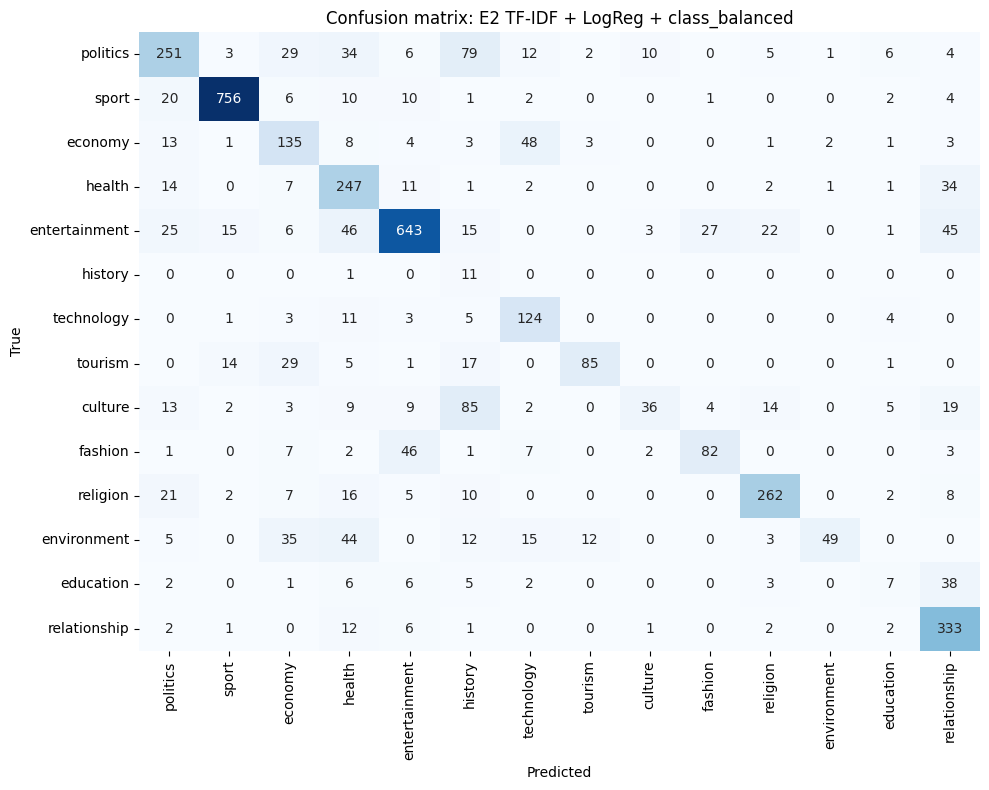

In [ ]:
BEST_NAME = results.iloc[0]['experiment']
print('Best model by macro F1:', BEST_NAME)

name_to_pred = {
    'E1 TF-IDF + LogReg': y_pred_lr,
    'E2 TF-IDF + LogReg + class_balanced': y_pred_lr_cl,
    'E3 TF-IDF + LinearSVM': y_pred_svm,
    'E4 BiGRU + OwnW2V50':   y_pred_e4,
    'E5 BiGRU + PreW2V50':   y_pred_e5,
    'E6 BiGRU + PreW2V100':  y_pred_e6,
    'E7 CNN + PreW2V100':    y_pred_e7,
}
y_pred_best = name_to_pred[BEST_NAME]

cm = confusion_matrix(y_te_idx, y_pred_best)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix: {BEST_NAME}')
plt.tight_layout(); plt.show()

Per-class F1 (worst first):
        class     f1  test_support
      history 0.0853            12
    education 0.1373            70
      culture 0.2846           201
  environment 0.4298           175
      economy 0.5510           222
      fashion 0.6189           151
     politics 0.6205           442
       health 0.6407           320
      tourism 0.6693           152
   technology 0.6795           151
 relationship 0.7826           360
entertainment 0.8048           848
     religion 0.8099           333
        sport 0.9409           812


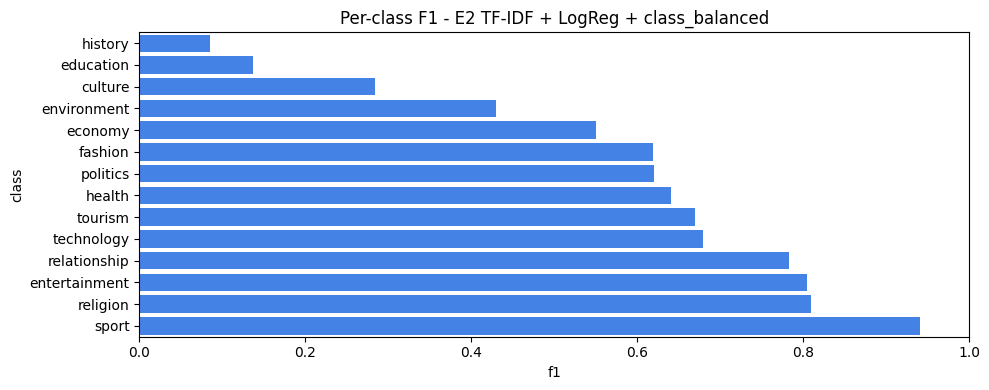

In [ ]:
_, _, f1_per_class, support = precision_recall_fscore_support(
    y_te_idx, y_pred_best, labels=list(range(NUM_CLASSES)), zero_division=0)
per_class = pd.DataFrame({'class': CLASS_NAMES, 'f1': f1_per_class, 'test_support': support})
per_class = per_class.sort_values('f1')
print('Per-class F1 (worst first):')
print(per_class.round(4).to_string(index=False))

plt.figure(figsize=(10, 4))
sns.barplot(data=per_class, y='class', x='f1', color='#2b7cff')
plt.xlim(0, 1); plt.title(f'Per-class F1 - {BEST_NAME}')
plt.tight_layout(); plt.show()

In [ ]:
wrong = np.where(y_pred_best != y_te_idx)[0]
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(wrong, size=min(8, len(wrong)), replace=False)
for i in sample_idx:
    true_name = CLASS_NAMES[y_te_idx[i]]
    pred_name = CLASS_NAMES[y_pred_best[i]]
    snippet = X_te_txt[i][:220]
    print(f'TRUE: {true_name:14s}  PRED: {pred_name:14s}')
    print(f'TEXT: {snippet}...\n')

TRUE: entertainment   PRED: health        
TEXT: igisubizo kubana bakiri bato kandi bafite impano zitandukanye abinyjije gikorwa yise children talents competition maman abana uzwi tantine brenda yiyemeje gufasha abana bafite hagati imyaka babarurirwa mpande enye rwanda...

TRUE: politics        PRED: history       
TEXT: kwibuka abanyarwanda ghana bibutse jenoside urubyiruko rusabwa kwigira mateka igikorwa cyabaye mata ghana gikorwa hifashishijwe ikoranabuhanga kubera icyorezo coronavirus ambasaderi rwanda ghana dr aisa kirabo kacyira ya...

TRUE: economy         PRED: relationship  
TEXT: zimwe nama zagufasha kubana neza umukoresha wawe uramutse uzikurikije abahanga imibanire abantu hari inama batanga wakora ubane neza umukoresha wawe umukoresha wawe munsi ashobora kuba umuntu ingenzi buzima bwawe bwose k...

TRUE: environment     PRED: history       
TEXT: inyoni canada amerika zagabanyutseho miliyari eshatu myaka bushakashatsi bwagaragaje inyoni bihugu zagabanyutseho myaka ishize ka

## 20. Export the best model for deployment

Save the best model, the tokenizer, the label map and a small config file into one `deploy/` folder. The Streamlit app loads these four files and nothing else.

In [ ]:
DEPLOY_DIR = f'{OUT_DIR}/deploy'
Path(DEPLOY_DIR).mkdir(parents=True, exist_ok=True)

classical_registry = {
    'E1 TF-IDF + LogReg'                    : (clf_lr,    vectorizer),
    'E2 TF-IDF + LogReg + class_balanced'   : (clf_lr_cl, vectorizer),
    'E3 TF-IDF + LinearSVM'                 : (clf_svm,   vectorizer),
}
keras_registry = {
    'E4 BiGRU + OwnW2V50'  : model_e4,
    'E5 BiGRU + PreW2V50'  : model_e5,
    'E6 BiGRU + PreW2V100' : model_e6,
    'E7 CNN + PreW2V100'   : model_e7,
}

if BEST_NAME in classical_registry:
    clf, vec = classical_registry[BEST_NAME]
    pickle.dump(clf, open(f'{DEPLOY_DIR}/model.pkl', 'wb'))
    pickle.dump(vec, open(f'{DEPLOY_DIR}/vectorizer.pkl', 'wb'))
    model_kind = 'classical'
elif BEST_NAME in keras_registry:
    keras_registry[BEST_NAME].save(f'{DEPLOY_DIR}/model.keras')
    pickle.dump(tokenizer, open(f'{DEPLOY_DIR}/tokenizer.pkl', 'wb'))
    model_kind = 'keras'
else:
    raise ValueError(f'BEST_NAME {BEST_NAME!r} not found in any registry. '
                     f'Update the registries above with the current experiment names.')

with open(f'{DEPLOY_DIR}/label_map.json', 'w') as f:
    json.dump({str(i): name for i, name in enumerate(CLASS_NAMES)}, f, indent=2)

deploy_config = {
    'model_name': BEST_NAME,
    'model_kind': model_kind,
    'max_len': CONFIG['MAX_LEN'],
    'min_token_len': CONFIG['MIN_TOKEN_LEN'],
    'num_classes': NUM_CLASSES,
}
with open(f'{DEPLOY_DIR}/config.json', 'w') as f:
    json.dump(deploy_config, f, indent=2)

with open(f'{DEPLOY_DIR}/stopwords.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(sorted(STOPWORDS)))

print('Deployment bundle written to', DEPLOY_DIR)
print(json.dumps(deploy_config, indent=2))

Deployment bundle written to /content/drive/MyDrive/KINNEWS/outputs/deploy
{
  "model_name": "E2 TF-IDF + LogReg + class_balanced",
  "model_kind": "classical",
  "max_len": 650,
  "min_token_len": 2,
  "num_classes": 14
}


## 21. Conclusion

The notebook starts from raw Kinyarwanda news articles, preprocesses them with a documented pipeline, splits them into train, validation and test, and compares six models side by side. The best model by macro F1 is exported as a small bundle that the Streamlit app loads to classify any Kinyarwanda text a user types in.

The report (separate file) reads the numbers in `outputs/summary.csv` and the artefacts in `outputs/` to write up the methodology, results, error analysis and limitations in the required format.

## 22. Model check

In [7]:
import json, pickle, re
from pathlib import Path

DEPLOY = Path(OUT_DIR) / 'deploy'

_model      = pickle.load(open(DEPLOY / 'model.pkl', 'rb'))
_vectorizer = pickle.load(open(DEPLOY / 'vectorizer.pkl', 'rb'))
_labels     = {int(k): v for k, v in json.load(open(DEPLOY / 'label_map.json')).items()}
_stops      = {w.strip().lower() for w in open(DEPLOY / 'stopwords.txt') if w.strip()}

_url_re       = re.compile(r'https?://\S+|www\.\S+')
_nonalpha_re  = re.compile(r'[^a-z\s]')
_multispace_re= re.compile(r'\s+')

def _preprocess(text):
    t = text.lower()
    t = _url_re.sub(' ', t)
    t = _nonalpha_re.sub(' ', t)
    t = _multispace_re.sub(' ', t).strip()
    return ' '.join(w for w in t.split() if w not in _stops and len(w) >= 2)

title   = input('Title:   ')
content = input('Content: ')
cleaned = _preprocess(f'{title} {content}')

if not cleaned:
    print('Nothing left after cleaning. Try longer input.')
else:
    X = _vectorizer.transform([cleaned])
    pred = int(_model.predict(X)[0])
    print(f'\nPredicted class: {_labels[pred]}')
    if hasattr(_model, 'predict_proba'):
        probs = _model.predict_proba(X)[0]
        top3 = sorted(enumerate(probs), key=lambda x: -x[1])[:3]
        print('Top 3:')
        for i, pr in top3:
            print(f'  {_labels[i]:14s} {pr:.3f}')

Title:   Umukino wahuje amakipe y'ubukombe ku isi uzwi nka el classico warangiye ikipe ya FC Barcelona inyagiyemo Real Madrid ibitego 8 ku busa.
Content: Tariki ya 25/10/2026, ku kibuga Camp Nou aho ikipe ya FC Barcelona yari yakiriye mukeba wayo Real Madrid, yaze kuyinyagira ibitego 8-0 aho abakinnyi nka Lamine Yamal yatsinze mo ibitego 3 ndetse na Rodri atsindamo ibitego 2. Birateganwa ko Lamine Yamal aribuze guhita anahabwa balon d'or kuri uyumunsi bitewe na performance nziza amaze igihe agira kuva season ya 2026/27 yatangira.

Predicted class: sport
Top 3:
  sport          0.863
  entertainment  0.037
  economy        0.015
